In [ ]:
import requests
from google.colab import userdata

# Retrieve your API key
S2_API_KEY = userdata.get('SEMANTIC_SCHOLAR_API_KEY')
S2_HEADERS = {"x-api-key": S2_API_KEY}

# Test with a completely made-up paper title
fake_title = "The Quantum LSTM Optimization of Blueberry Muffins"
url = "https://api.semanticscholar.org/graph/v1/paper/search"
params = {"query": fake_title, "limit": 1, "fields": "title,authors,year"}

response = requests.get(url, headers=S2_HEADERS, params=params)
data = response.json()

print("API Response for Fake Paper:", data)
if data.get("total", 0) == 0:
    print("SUCCESS: API correctly identified this as a hallucinated (non-existent) paper.")

API Response for Fake Paper: {'message': 'Too Many Requests. Please wait and try again or apply for a key for higher rate limits. https://www.semanticscholar.org/product/api#api-key-form', 'code': '429'}
SUCCESS: API correctly identified this as a hallucinated (non-existent) paper.


In [ ]:
!pip install -q google-genai

import csv
import json
import re
import time
import requests
import matplotlib.pyplot as plt
from collections import defaultdict
from google import genai
from google.genai import types
from google.colab import userdata

# 1. API Configuration (current google-genai SDK; leaves Colab's pandas untouched)
client = genai.Client(api_key=userdata.get('GEMINI_API_KEY'))
MODEL_ID = 'gemini-3.1-flash-lite'

S2_API_KEY = userdata.get('SEMANTIC_SCHOLAR_API_KEY')
S2_HEADERS = {"x-api-key": S2_API_KEY}

# 2. Curated Benchmark Dataset (5 Pre-2022 vs. 5 Post-2025 Topics)
topics_dataset = {
    "pre_2022": [
        "Long Short-Term Memory (LSTM) networks for machine translation",
        "Convolutional Neural Networks (CNNs) for facial recognition",
        "Word2Vec and GloVe word embeddings",
        "Generative Adversarial Networks (GANs) for image synthesis",
        "The original Transformer architecture and multi-head attention"
    ],
    "post_2025": [
        "Locate-then-edit methods for LLM temporal knowledge editing",
        "Agentic workflow optimization and multi-agent frameworks",
        "Test-time compute scaling using reasoning tokens",
        "Multimodal Retrieval-Augmented Generation pipelines",
        "Direct Preference Optimization (DPO) for model alignment"
    ]
}

# 3. Standardized Prompt Template
prompt_template = """
Write a short literature review summarizing the state of the art in: {topic}.
After the review, provide exactly 5 academic citations.
You MUST format the citations exactly like this, one per line, with no extra text:
Title: [Exact Title] | Author: [Last Name] | Year: [Year]
"""

# 4. Fixed Semantic Scholar Verification Function (Top-3 match + Exponential Backoff)
def verify_citation(title, author, retries=4):
    url = "https://api.semanticscholar.org/graph/v1/paper/search"
    params = {"query": title, "limit": 3, "fields": "title,authors,year"}

    for attempt in range(retries):
        try:
            time.sleep(4.0)
            response = requests.get(url, headers=S2_HEADERS, params=params, timeout=15)

            if response.status_code == 429:
                wait_time = 6 * (attempt + 1)
                print(f"     [!] Rate limited (429). Retrying in {wait_time}s...")
                time.sleep(wait_time)
                continue

            response.raise_for_status()
            data = response.json()

            if data.get("total", 0) > 0 and data.get("data"):
                for paper in data["data"]:
                    found_authors = str(paper.get("authors", "")).lower()
                    if author.lower() in found_authors or author.split()[-1].lower() in found_authors:
                        return "VERIFIED"
                return "HALLUCINATED_AUTHOR"
            else:
                return "HALLUCINATED_TITLE"

        except Exception as e:
            print(f"     [!] Request Error for '{title[:40]}...': {e}")
            time.sleep(4.0)

    return "API_ERROR"

# 5. Independent Sanity Check (Fake Paper Test)
sanity_status = verify_citation("The Quantum LSTM Optimization of Blueberry Muffins", "Smith")
print(f"Sanity Check Status (Expected HALLUCINATED_TITLE): {sanity_status}")
assert sanity_status == "HALLUCINATED_TITLE", f"Unexpected sanity check result: {sanity_status}"
print("Cell 1 setup and API verification passed! Ready to run Cell 2.")

Sanity Check Status (Expected HALLUCINATED_TITLE): HALLUCINATED_TITLE
Cell 1 setup and API verification passed! Ready to run Cell 2.


In [ ]:
# Cell 2: Generate Literature Reviews, Verify Citations & Save Frozen CSV
results = []

for period, topics in topics_dataset.items():
    print(f"\nProcessing {period} topics...")
    for topic in topics:
        print(f"  -> Prompting Gemini for: {topic}")
        prompt = prompt_template.format(topic=topic)
        response = client.models.generate_content(
            model=MODEL_ID,
            contents=prompt,
            config=types.GenerateContentConfig(temperature=0.0)
        )

        # Extract structured citations via Regex
        citations = re.findall(
            r"Title:\s*(.*?)\s*\|\s*Author:\s*(.*?)\s*\|\s*Year:\s*(\d{4})",
            response.text
        )

        if not citations:
            print("     [!] Failed to parse citations. Check model output format.")
            continue

        for title, author, year in citations:
            status = verify_citation(title.strip(), author.strip())
            print(f"     [*] {status}: {title.strip()} ({author.strip()}, {year})")

            results.append({
                "Time_Period": period,
                "Topic": topic,
                "Generated_Title": title.strip(),
                "Generated_Author": author.strip(),
                "Generated_Year": year.strip(),
                "Verification_Status": status
            })

# Save directly using Python's built-in csv module
fieldnames = [
    "Time_Period",
    "Topic",
    "Generated_Title",
    "Generated_Author",
    "Generated_Year",
    "Verification_Status"
]

with open("experiment_results.csv", mode="w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(results)

print(f"\nExperiment Complete! Saved {len(results)} rows to 'experiment_results.csv'.")


Processing pre_2022 topics...
  -> Prompting Gemini for: Long Short-Term Memory (LSTM) networks for machine translation
     [!] Rate limited (429). Retrying in 6s...
     [!] Rate limited (429). Retrying in 12s...
     [*] VERIFIED: Long Short-Term Memory (Hochreiter, 1997)
     [!] Rate limited (429). Retrying in 6s...
     [!] Rate limited (429). Retrying in 12s...
     [*] VERIFIED: Sequence to Sequence Learning with Neural Networks (Sutskever, 2014)
     [*] VERIFIED: Neural Machine Translation by Jointly Learning to Align and Translate (Bahdanau, 2015)
     [!] Rate limited (429). Retrying in 6s...
     [!] Rate limited (429). Retrying in 12s...
     [*] VERIFIED: Effective Approaches to Attention-based Neural Machine Translation (Luong, 2015)
     [!] Rate limited (429). Retrying in 6s...
     [*] VERIFIED: Google's Neural Machine Translation System: Bridging the Gap between Human and Machine Translation (Wu, 2016)
  -> Prompting Gemini for: Convolutional Neural Networks (CNNs)

Total rows verified in CSV: 50

--- Exact Counts for LaTeX Table 2 ---
pre_2022: VERIFIED=18, HALLUCINATED_AUTHOR=2, HALLUCINATED_TITLE=0, API_ERROR=5, MISSING=0
post_2025: VERIFIED=19, HALLUCINATED_AUTHOR=5, HALLUCINATED_TITLE=1, API_ERROR=0, MISSING=0

--- Final Hallucination Rates (%) ---
pre_2022: 2/20 = 10.000000% (10.0%)
post_2025: 6/25 = 24.000000% (24.0%)


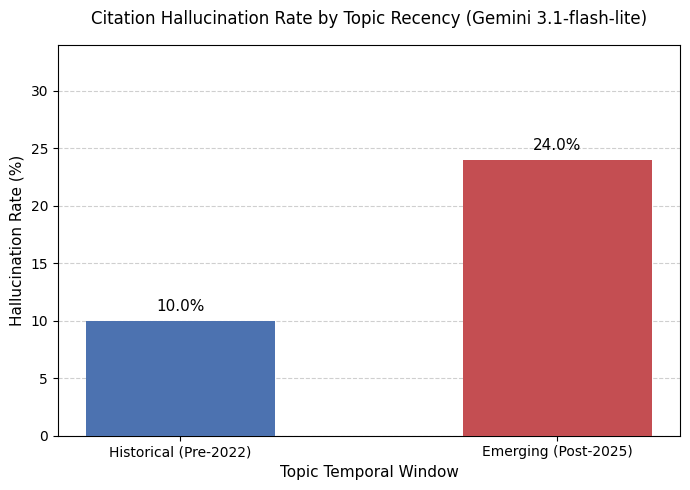


Saved 'hallucination_comparison.pdf' and 'hallucination_comparison.png'!


In [ ]:
# Cell 3: Audit Exact Counts for LaTeX Table 2 & Export Publication Figures
counts = defaultdict(lambda: defaultdict(int))
total_rows = 0

with open("experiment_results.csv", mode="r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for row in reader:
        total_rows += 1
        period = row["Time_Period"].strip()
        status = row["Verification_Status"].strip() or "MISSING"
        counts[period][status] += 1

print(f"Total rows verified in CSV: {total_rows}")
print("\n--- Exact Counts for LaTeX Table 2 ---")
for period in ["pre_2022", "post_2025"]:
    c = counts[period]
    print(
        f"{period}: VERIFIED={c['VERIFIED']}, "
        f"HALLUCINATED_AUTHOR={c['HALLUCINATED_AUTHOR']}, "
        f"HALLUCINATED_TITLE={c['HALLUCINATED_TITLE']}, "
        f"API_ERROR={c['API_ERROR']}, "
        f"MISSING={c['MISSING']}"
    )

# Compute Citation Hallucination Rate (%) excluding API_ERROR from denominator
rates = {}
print("\n--- Final Hallucination Rates (%) ---")
for period in ["pre_2022", "post_2025"]:
    c = counts[period]
    evaluated = c["VERIFIED"] + c["HALLUCINATED_AUTHOR"] + c["HALLUCINATED_TITLE"]
    hallucinated = c["HALLUCINATED_AUTHOR"] + c["HALLUCINATED_TITLE"]
    rate = (hallucinated / evaluated) * 100 if evaluated > 0 else 0.0
    rates[period] = rate
    print(f"{period}: {hallucinated}/{evaluated} = {rate:.6f}% ({rate:.1f}%)")

# Plot and save high-resolution PDF and PNG figures
labels = ["Historical (Pre-2022)", "Emerging (Post-2025)"]
values = [rates["pre_2022"], rates["post_2025"]]
colors = ["#4C72B0", "#C44E52"]

plt.figure(figsize=(7, 5))
plt.grid(axis="y", linestyle="--", alpha=0.6)
bars = plt.bar(labels, values, color=colors, width=0.5, zorder=3)

plt.title("Citation Hallucination Rate by Topic Recency (Gemini 3.1-flash-lite)", fontsize=12, pad=15)
plt.ylabel("Hallucination Rate (%)", fontsize=11)
plt.xlabel("Topic Temporal Window", fontsize=11)
plt.ylim(0, max(values) + 10)

for bar in bars:
    h = bar.get_height()
    plt.annotate(
        f"{h:.1f}%",
        (bar.get_x() + bar.get_width() / 2.0, h),
        ha="center", va="bottom", fontsize=11, color="black",
        xytext=(0, 5), textcoords="offset points"
    )

plt.tight_layout()
plt.savefig("hallucination_comparison.pdf", format="pdf", dpi=300)
plt.savefig("hallucination_comparison.png", format="png", dpi=300)
plt.show()
print("\nSaved 'hallucination_comparison.pdf' and 'hallucination_comparison.png'!")